### **Objetivo:** 
análise exploratória de dados referentes a direitos LBGT em âmibto global e regional (com foco na américa do sul), e observação de possíveis relações entre média de IDH e a média de igualdade/direitos LGBT entre países da américa do sul.



In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.projeto_piloto_direitos_lgbt AS
SELECT
  `Region ID` AS id_regiao,
  `Name` AS pais,
  `EI` AS indice_igualdade,
  `EI Legal` AS indice_igualdade_legal,
  `EI PO` AS indice_igualdade_pessoas,
  `Rank` AS ranking_global
FROM read_files(
  '/Workspace/Users/lauranovais9@gmail.com/equaldex_equality_index.csv',
  format => 'csv',
  header => true,
  inferSchema => true
)



num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT * FROM workspace.default.projeto_piloto_direitos_lgbt


id_regiao,pais,indice_igualdade,indice_igualdade_legal,indice_igualdade_pessoas,ranking_global
IS,Iceland,93,96,90,1
NO,Norway,89,90,87,2
UY,Uruguay,87,100,74,3
ES,Spain,83,100,67,4
DK,Denmark,82,94,69,5
MT,Malta,80,100,61,6
NZ,New Zealand,80,95,65,7
CL,Chile,80,100,60,8
AD,Andorra,80,86,74,9
DE,Germany,80,99,60,10


uma vez importados os dados, agora vamos visualizar as propriedades da tabela

In [0]:
%sql
DESCRIBE workspace.default.projeto_piloto_direitos_lgbt

col_name,data_type,comment
id_regiao,string,null
pais,string,null
indice_igualdade,int,null
indice_igualdade_legal,int,null
indice_igualdade_pessoas,int,null
ranking_global,int,null


verificando se existem dados nulos

In [0]:
%sql
SELECT * FROM workspace.default.projeto_piloto_direitos_lgbt
WHERE id_regiao IS NULL
AND pais IS NULL
AND indice_igualdade IS NULL
AND indice_igualdade_legal IS NULL
AND indice_igualdade_pessoas IS NULL
AND ranking_global IS NULL

id_regiao,pais,indice_igualdade,indice_igualdade_legal,indice_igualdade_pessoas,ranking_global


alterando ou limpando colunas

In [0]:

%sql
SELECT
pais, indice_igualdade, ranking_global
FROM
workspace.default.projeto_piloto_direitos_lgbt;


 

pais,indice_igualdade,ranking_global
Iceland,93,1
Norway,89,2
Uruguay,87,3
Spain,83,4
Denmark,82,5
Malta,80,6
New Zealand,80,7
Chile,80,8
Andorra,80,9
Germany,80,10


contagem de dados da tabela filtrada

In [0]:
%sql
SELECT
    COUNT(*) AS total_linhas,
    COUNT(pais) AS total_paises,
    COUNT(indice_igualdade) AS total_indices,
    COUNT (ranking_global) AS total_ranking,
    COUNT(DISTINCT pais) AS total_paises_distintos
FROM
workspace.default.projeto_piloto_direitos_lgbt_filtro

total_linhas,total_paises,total_indices,total_ranking,total_paises_distintos
197,197,197,197,197


analise estatística dos dados gerais da tabela

In [0]:
%sql
SELECT
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(VAR_POP(indice_igualdade), 2) AS variancia_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade
FROM
workspace.default.projeto_piloto_direitos_lgbt
    


media_ii,max_ii,min_ii,mediana_ii,moda_ii,variancia_ii,desvio_padrao_ii,media_legal,mediana_legal,media_pessoas,corr_lei_sociedade
39.62,93,1,39.0,13,537.97,23.25,45.4,45.0,34.91,0.768


análise estatística dos dados dos países da américa do sul

In [0]:
%sql
SELECT
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(VAR_POP(indice_igualdade), 2) AS variancia_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade

FROM
workspace.default.projeto_piloto_direitos_lgbt

WHERE
pais IN ('Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela')


    


media_ii,max_ii,min_ii,mediana_ii,moda_ii,variancia_ii,desvio_padrao_ii,media_legal,mediana_legal,media_pessoas,corr_lei_sociedade
61.33,87,35,63.5,53,269.06,17.13,73.5,86.5,49.0,0.436


manipulando linhas e unindo resultados:

In [0]:
%sql
SELECT
'mundo (global)' AS regiao,
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade
FROM workspace.default.projeto_piloto_direitos_lgbt

UNION ALL
SELECT
'américa do sul' AS regiao,
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade

FROM
workspace.default.projeto_piloto_direitos_lgbt

WHERE
pais IN ('Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela')


regiao,media_ii,max_ii,min_ii,mediana_ii,moda_ii,desvio_padrao_ii,media_legal,mediana_legal,media_pessoas,corr_lei_sociedade
mundo (global),39.62,93,1,39.0,10,23.25,45.4,45.0,34.91,0.768
américa do sul,61.33,87,35,63.5,53,17.13,73.5,86.5,49.0,0.436


agora salvando a visualização criada acima:


In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.direitos_lgbt_comparacao_global_sulamerica
AS

SELECT
'mundo (global)' AS regiao,
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade
FROM workspace.default.projeto_piloto_direitos_lgbt

UNION ALL
SELECT
'américa do sul' AS regiao,
ROUND(AVG(indice_igualdade), 2) AS media_ii,
MAX(indice_igualdade) AS max_ii,
MIN(indice_igualdade) AS min_ii,
MEDIAN(indice_igualdade) AS mediana_ii,
MODE(indice_igualdade) AS moda_ii,
ROUND(STDDEV(indice_igualdade), 2) AS desvio_padrao_ii,
ROUND(AVG(indice_igualdade_legal), 2) AS media_legal,
ROUND(MEDIAN(indice_igualdade_legal), 2) AS mediana_legal,
ROUND(AVG(indice_igualdade_pessoas), 2) AS media_pessoas,
ROUND(CORR(indice_igualdade_legal, indice_igualdade_pessoas), 3) AS corr_lei_sociedade

FROM
workspace.default.projeto_piloto_direitos_lgbt

WHERE
pais IN ('Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela')


num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT *   
FROM workspace.default.direitos_lgbt_comparacao_global_sulamerica

regiao,media_ii,max_ii,min_ii,mediana_ii,moda_ii,desvio_padrao_ii,media_legal,mediana_legal,media_pessoas,corr_lei_sociedade
américa do sul,61.33,87,35,63.5,53,17.13,73.5,86.5,49.0,0.436
mundo (global),39.62,93,1,39.0,10,23.25,45.4,45.0,34.91,0.768


por enquanto terminamos com os dados de direitos lgbt agora vamos tratar os dados de IDH

In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.indice_idh_global
AS
SELECT
  `Country Name` AS pais,
  `Country Code` AS cod_pais,
  `Year` AS ano,
  ROUND(`Value`/1000000000, 3) AS valor
FROM read_files(
  '/Workspace/Users/lauranovais9@gmail.com/gdp.csv',
  format => 'csv',
  header => true,
  inferSchema => true
)



num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT(*)
FROM workspace.default.indice_idh_global

pais,cod_pais,ano,valor
Afghanistan,AFG,2000,3.521
Afghanistan,AFG,2001,2.814
Afghanistan,AFG,2002,3.826
Afghanistan,AFG,2003,4.521
Afghanistan,AFG,2004,5.225
Afghanistan,AFG,2005,6.203
Afghanistan,AFG,2006,6.972
Afghanistan,AFG,2007,9.748
Afghanistan,AFG,2008,10.109
Afghanistan,AFG,2009,12.416


In [0]:
%sql
DESCRIBE workspace.default.indice_idh_global

col_name,data_type,comment
pais,string,null
cod_pais,string,null
ano,int,null
valor,double,null


In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.indice_idh_global_2021  
AS
SELECT (*)
FROM
workspace.default.indice_idh_global
WHERE
ano = 2021


num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT * FROM workspace.default.indice_idh_global_2021

pais,cod_pais,ano,valor
Afghanistan,AFG,2021,14.266
Africa Eastern and Southern,AFE,2021,1086.772
Africa Western and Central,AFW,2021,845.993
Albania,ALB,2021,17.931
Algeria,DZA,2021,186.265
American Samoa,ASM,2021,0.75
Andorra,AND,2021,3.325
Angola,AGO,2021,66.505
Antigua and Barbuda,ATG,2021,1.601
Arab World,ARB,2021,2969.117


In [0]:
%sql
SELECT
    COUNT(*) AS total_linhas,
    COUNT(pais) AS total_paises,
    COUNT(DISTINCT(pais)) AS total_paises_distintos
FROM
    workspace.default.indice_idh_global_2021

total_linhas,total_paises,total_paises_distintos
256,256,256


In [0]:
%sql
SELECT *
FROM workspace.default.indice_idh_global_2021
WHERE pais IN ('Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela')

pais,cod_pais,ano,valor
Argentina,ARG,2021,487.903
Bolivia,BOL,2021,40.406
Brazil,BRA,2021,1670.647
Chile,CHL,2021,315.515
Colombia,COL,2021,318.525
Ecuador,ECU,2021,107.435
Guyana,GUY,2021,8.041
Paraguay,PRY,2021,39.951
Peru,PER,2021,226.354
Suriname,SUR,2021,3.081


In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.direitos_vs_pib_2021 AS
SELECT
d.pais AS pais, 
d.indice_igualdade, 
d.indice_igualdade_legal, 
d.indice_igualdade_pessoas, 
i.valor AS pib_bilhoes_usd

FROM workspace.default.projeto_piloto_direitos_lgbt d  
INNER JOIN workspace.default.indice_idh_global_2021 i
ON LOWER(TRIM(d.pais)) = LOWER(TRIM(i.pais));

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT * 
FROM workspace.default.direitos_vs_pib_2021 ORDER BY indice_igualdade DESC;

pais,indice_igualdade,indice_igualdade_legal,indice_igualdade_pessoas,pib_bilhoes_usd
Iceland,93,96,90,25.798
Norway,89,90,87,503.368
Uruguay,87,100,74,60.761
Spain,83,100,67,1445.652
Denmark,82,94,69,405.688
Andorra,80,86,74,3.325
New Zealand,80,95,65,253.644
Chile,80,100,60,315.515
Malta,80,100,61,18.124
Germany,80,99,60,4278.504


In [0]:
%sql
CREATE OR REPLACE TABLE
workspace.default.direitos_sulamerica_vs_pib_2021
AS
SELECT *
FROM
workspace.default.direitos_vs_pib_2021
WHERE pais IN ('Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela')

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT *
FROM workspace.default.direitos_sulamerica_vs_pib_2021

pais,indice_igualdade,indice_igualdade_legal,indice_igualdade_pessoas,pib_bilhoes_usd
Argentina,75,89,61,487.903
Bolivia,63,87,38,40.406
Brazil,75,94,56,1670.647
Chile,80,100,60,315.515
Colombia,71,92,50,318.525
Ecuador,64,86,42,107.435
Guyana,39,24,53,8.041
Paraguay,35,38,31,39.951
Peru,53,62,44,226.354
Suriname,41,60,23,3.081


unindo todas as tabelas em uma única tabela final



In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%sql
SELECT
    'Mundo (Global)' AS escopo,
    COUNT(*) AS total_paises,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade), 3) AS corr_pib_vs_igualdade_geral,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade_legal), 3) AS corr_pib_vs_igualdade_legal,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade_pessoas), 3) AS corr_pib_vs_igualdade_op_publica
    FROM workspace.default.direitos_vs_pib_2021
    UNION ALL
    SELECT
    'Sul America' AS escopo,
    COUNT(*) AS total_paises,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade), 3) AS corr_pib_vs_igualdade_geral,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade_legal), 3) AS corr_pib_vs_igualdade_legal,
    ROUND(CORR(pib_bilhoes_usd, indice_igualdade_pessoas), 3) AS corr_pib_vs_igualdade_op_publica
    FROM workspace.default.direitos_sulamerica_vs_pib_2021;


escopo,total_paises,corr_pib_vs_igualdade_geral,corr_pib_vs_igualdade_legal,corr_pib_vs_igualdade_op_publica
Mundo (Global),167,0.189,0.151,0.222
Sul America,11,0.406,0.385,0.309


###`Gráfico` scatterplot - correlacionando PIB vs índice de igualdade:
**objetivo:** mostrar visualmente se/como o PIB influencia o indice de igualdade, e identificar outliers
*usaremos a escala logaritmica para auxiliar na visualização de dados muito discrepantes (como os PIBS dos países)*


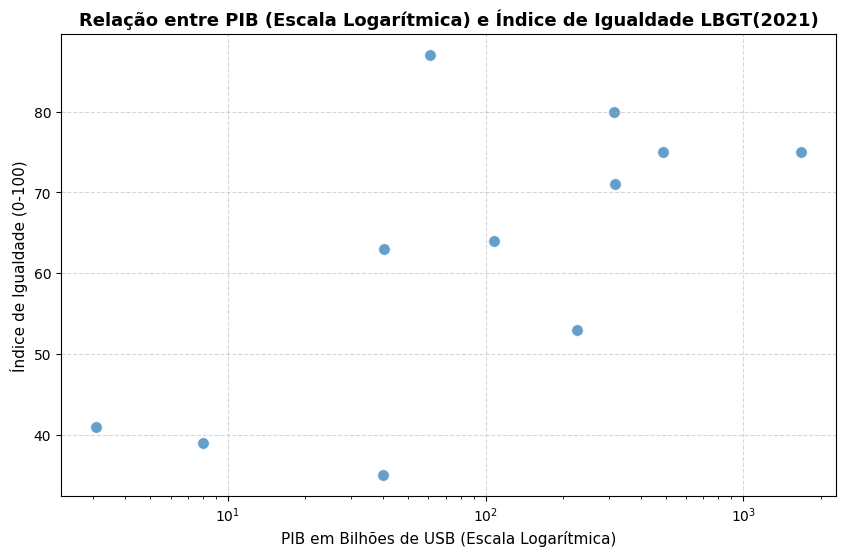

In [0]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 1.carregar os dados workspace para pandas
df_pib_igualdade = spark.table("workspace.default.direitos_sulamerica_vs_pib_2021").toPandas()

### 2.configurar visuais do gráfico
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_pib_igualdade,
    x='pib_bilhoes_usd',
    y='indice_igualdade',
    alpha=0.7,
    color='#1f77b4',
    s=70
)
### 2.1 eixo x em escala log (devio à alta diferênça de valores)
plt.xscale('log')

### 3. títulos e rótulos
plt.title('Relação entre PIB (Escala Logarítmica) e Índice de Igualdade LBGT(2021)', fontsize=13, fontweight='bold')
plt.xlabel('PIB em Bilhões de USB (Escala Logarítmica)', fontsize=11)
plt.ylabel('Índice de Igualdade (0-100)', fontsize=11)
plt.grid(True, linestyle ='--', alpha=0.5)

###exibir o gráfico
plt.show()

###Gráfico Barras Agrupadas: mundo vs. América do Sul
- **objetivo**: ilustrar a comparação ente as médias do indice gera. legislação e opinião publica, destacando a divergência entre os parâtros em países da américa do sul

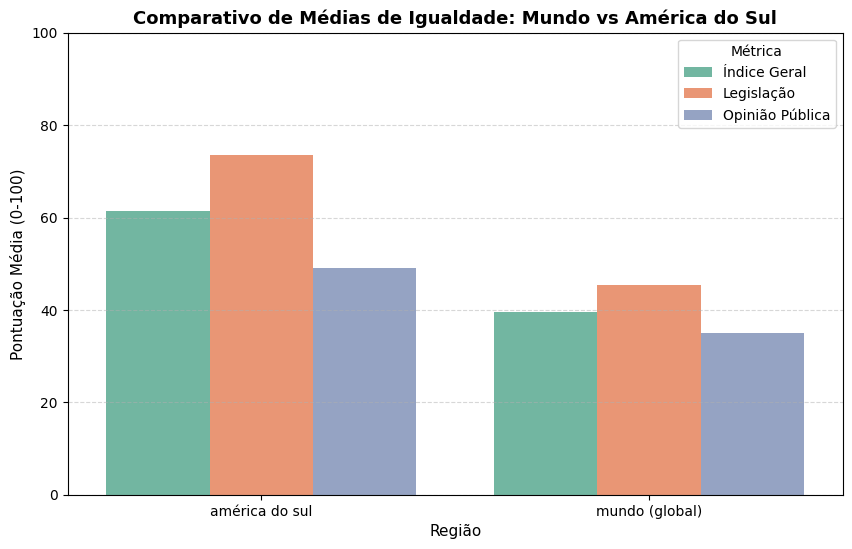

In [0]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_comp = spark.table("workspace.default.direitos_lgbt_comparacao_global_sulamerica").toPandas()

### reorganizando os dados para o formato do seaborn (melt)
df_plot = df_comp[['regiao', 'media_ii', 'media_legal', 'media_pessoas',]].melt(
    id_vars='regiao',
    var_name = 'metrica',
    value_name = 'nota'
)

### renomeando as legendas
df_plot['metrica'] = df_plot['metrica'].map({
    'media_ii': 'Índice Geral',
    'media_legal': 'Legislação',
    'media_pessoas': 'Opinião Pública'
})

### gerando o gráfico
plt.figure(figsize=(10,6))
sns.barplot(data=df_plot, x='regiao', y='nota', hue='metrica', palette='Set2')

plt.title('Comparativo de Médias de Igualdade: Mundo vs América do Sul', fontsize=13, fontweight='bold')
plt.xlabel('Região', fontsize=11)
plt.ylabel('Pontuação Média (0-100)', fontsize=11)
plt.ylim(0,100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title= 'Métrica')

plt.show()

###gráfico de caixa (boxplot): distribuição e dispersão regional
**objetivo**: mostrar a amplitude, a mediana e a dispersão dos dados de igualdade. evidenciar como a América do Sul tem um nível de igualdade mais elevado, porém com um intervalo de variabilidade concentrado em notas mais altas que a média mundial.


/home/spark-5399c30d-4c36-443b-b4db-13/.ipykernel/67/command-5871532565046143-3676223031:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_boxplot, x='Regiao', y='indice_igualdade', palette='Pastel1', width=0.4)


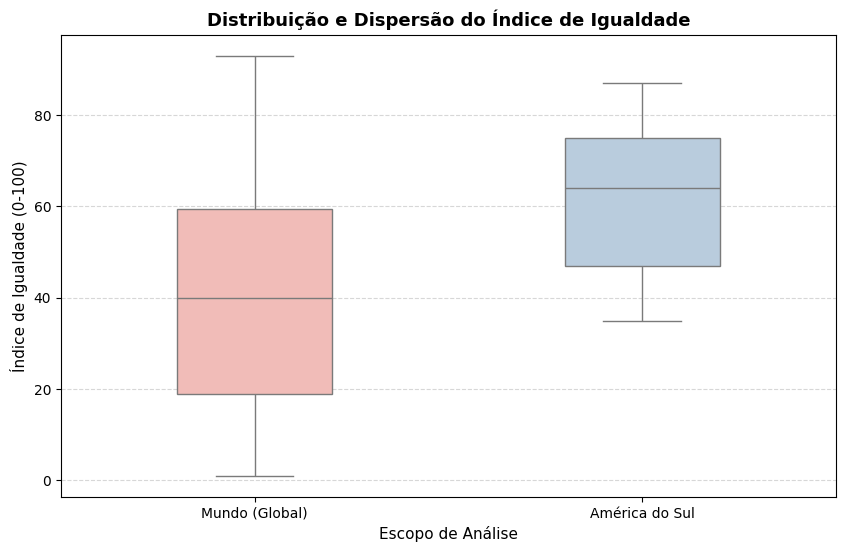

In [0]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### carrgando e identificando cada escopo:
df_global = spark.table("workspace.default.direitos_vs_pib_2021").toPandas()
df_global['Regiao'] = 'Mundo (Global)'

df_sa = spark.table("workspace.default.direitos_sulamerica_vs_pib_2021").toPandas()
df_sa['Regiao'] = 'América do Sul'

### unindo as duas bases
df_boxplot = pd.concat([df_global, df_sa])

###definições do gráfico
plt.figure(figsize=(10,6))
sns.boxplot(data=df_boxplot, x='Regiao', y='indice_igualdade', palette='Pastel1', width=0.4)

plt.title('Distribuição e Dispersão do Índice de Igualdade', fontsize=13, fontweight='bold')
plt.xlabel('Escopo de Análise', fontsize=11)
plt.ylabel('Índice de Igualdade (0-100)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

###Gráfico de Barras Horizontal: Ranking dos Países da América do Sul
**objetivo:** apresentar ordenação direta dos 12 países sul-americanos com o valor exado dad pontuação em cada barra

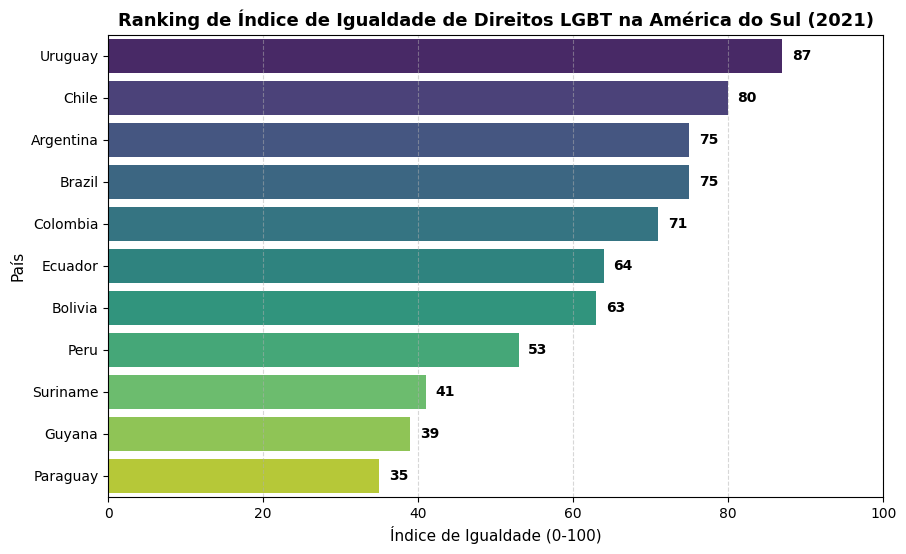

In [0]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_sa_rank = spark.table("workspace.default.direitos_sulamerica_vs_pib_2021").toPandas()
df_sa_rank = df_sa_rank.sort_values('indice_igualdade', ascending=False)

plt.figure(figsize=(10,6))
barplot = sns.barplot(data=df_sa_rank, x='indice_igualdade', y='pais', palette='viridis')

### adicionando números no final de cada barra:
for p in barplot.patches:
    width = p.get_width()
    plt.text(
        width + 1.2,
        p.get_y() + p.get_height() / 2,
        f'{width:.0f}',
        va='center',
        fontweight='bold',
        color='black'
    )

plt.title('Ranking de Índice de Igualdade de Direitos LGBT na América do Sul (2021)', fontsize=13, fontweight='bold')
plt.xlabel('Índice de Igualdade (0-100)', fontsize=11)
plt.ylabel('País', fontsize=11)
plt.xlim(0,100)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.show()

reavaliando o escopo do estudo (foco na comparação de indices de igualdade e pibs de paises das américas e da américa do sul) surge a necessidade de novas manipulações dos dados já tratados, bem como a alteração de um gráfico e a criação de um novo.

### tabela de escopo américas:

In [0]:
%sql 
CREATE OR REPLACE TABLE 
workspace.default.direitos_americas_vs_pib_2021 AS 
SELECT 
    d.pais AS pais, d.indice_igualdade, 
    d.indice_igualdade_legal, 
    d.indice_igualdade_pessoas, 
    COALESCE(i.valor, 15.0) AS pib_bilhoes_usd 
    FROM workspace.default.projeto_piloto_direitos_lgbt d 
    LEFT JOIN workspace.default.indice_idh_global_2021 i 
        ON LOWER(TRIM(d.pais)) = LOWER(TRIM(i.pais)) 
        OR (LOWER(d.pais) LIKE '%united states%' AND LOWER(i.pais) LIKE '%united states%') 
        OR (LOWER(d.pais) LIKE '%venezuela%' AND LOWER(i.pais) LIKE '%venezuela%') 
        OR (LOWER(d.pais) LIKE '%bolivia%' AND LOWER(i.pais) LIKE '%bolivia%') 
        WHERE d.pais IN ( 'United States', 'Canada', 'Mexico', 'Costa Rica', 'Panama', 'El Salvador', 'Guatemala', 'Honduras', 'Nicaragua', 'Belize', 'Cuba', 'Dominican Republic', 'Jamaica', 'Haiti', 'Bahamas', 'Barbados', 'Trinidad and Tobago', 'Antigua and Barbuda', 'Dominica', 'Grenada', 'Saint Kitts and Nevis', 'Saint Lucia', 'Saint Vincent and the Grenadines', 'Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela' );

num_affected_rows,num_inserted_rows


agora criando os gráficos complementares:
### Scatterplot Américas: Igualdade LGBTQIAPN+ vs PIB
**objetivo:** comparação visual dos índices de igualdade vs o pib das américas

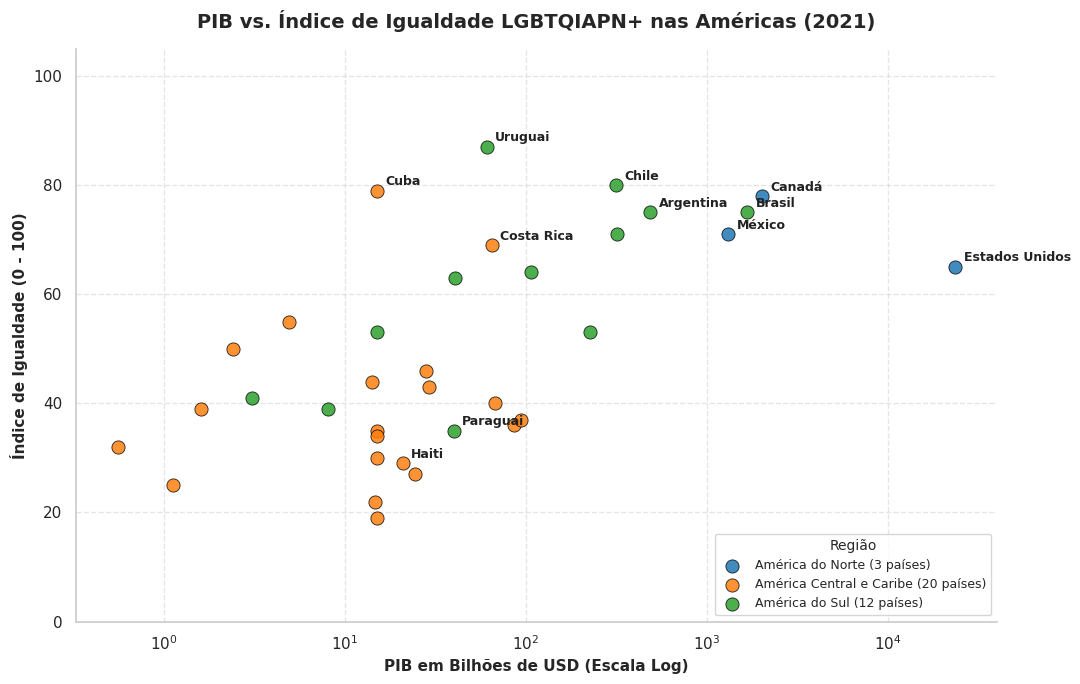

In [0]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

plt.clf() 
plt.close('all') 

df_americas = spark.table("workspace.default.direitos_americas_vs_pib_2021").toPandas() 

def classificar_regiao_oficial(pais_nome): 
    c = str(pais_nome).strip().lower() 
    
    # América do Norte (3 países)
    if any(n in c for n in ['united states', 'canada', 'mexico', 'estados unidos', 'canadá', 'méxico']):
        return 'América do Norte' 
    # América do Sul (12 países) 
    elif any(n in c for n in ['argentina', 'bolivia', 'brazil', 'chile', 'colombia', 'ecuador', 'guyana', 'paraguay', 'peru', 'suriname', 'uruguay', 'venezuela', 'brasil', 'bolívia', 'guiana', 'paraguai']):
        return 'América do Sul' 
    # América Central e Caribe (20 países) 
    else:
        return 'América Central e Caribe' 

df_americas['regiao'] = df_americas['pais'].apply(classificar_regiao_oficial) 

# Dicionário de tradução 
pt_names = { 
    'United States': 'Estados Unidos', 'Canada': 'Canadá', 'Mexico': 'México', 'Brazil': 'Brasil', 'Argentina': 'Argentina', 'Chile': 'Chile', 'Colombia': 'Colômbia', 'Peru': 'Peru', 'Ecuador': 'Equador', 'Uruguay': 'Uruguai', 'Venezuela': 'Venezuela', 'Paraguay': 'Paraguai', 'Bolivia': 'Bolívia', 'Guyana': 'Guiana', 'Suriname': 'Suriname', 'Costa Rica': 'Costa Rica', 'Panama': 'Panamá', 'El Salvador': 'El Salvador', 'Guatemala': 'Guatemala', 'Honduras': 'Honduras', 'Nicaragua': 'Nicarágua', 'Belize': 'Belize', 'Cuba': 'Cuba', 'Dominican Republic': 'Rep. Dominicana', 'Jamaica': 'Jamaica', 'Trinidad and Tobago': 'Trinidad e Tobago', 'Bahamas': 'Bahamas', 'Barbados': 'Barbados', 'Haiti': 'Haiti' 
    } 
df_americas['pais_pt'] = df_americas['pais'].map(pt_names).fillna(df_americas['pais']) 

fig, ax = plt.subplots(figsize=(11, 7)) 
sns.set_theme(style='whitegrid', font='DejaVu Sans') 
colors = { 
    'América do Norte': '#1f77b4', # Azul 
    'América Central e Caribe': '#ff7f0e', # Laranja 
    'América do Sul': '#2ca02c' # Verde 
    } 

ordem_regioes = ['América do Norte', 'América Central e Caribe', 'América do Sul']
for reg in ordem_regioes: 
    grupo = df_americas[df_americas['regiao'] == reg] 
    if len(grupo) > 0: 
        ax.scatter( grupo['pib_bilhoes_usd'], 
                    grupo['indice_igualdade'], label=f"{reg} ({len(grupo)} países)", color=colors[reg], marker='o', 
                    s=90, 
                    alpha=0.85, 
                    edgecolors='black', 
                    linewidths=0.6 
                    ) 
ax.set_xscale('log') 
ax.set_ylim(0, 105) 

# Rótulos 
key_highlights = ['United States', 'Canada', 'Mexico', 'Uruguay', 'Brazil', 'Argentina', 'Costa Rica', 'Chile', 'Haiti', 'Paraguay', 'Cuba', 'Estados Unidos', 'Brasil', 'Canadá', 'México'] 
for _, row in df_americas.iterrows(): 
    if row['pais'] in key_highlights or row['pais_pt'] in key_highlights: 
        ax.annotate( 
                    str(row['pais_pt']), (float(row['pib_bilhoes_usd']),
                    float(row['indice_igualdade'])), 
                    xytext=(6, 4), 
                    textcoords='offset points', 
                    fontsize=9, 
                    fontweight='bold', 
                    color='#222222' ) 
# Títulos
ax.set_title('PIB vs. Índice de Igualdade LGBTQIAPN+ nas Américas (2021)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('PIB em Bilhões de USD (Escala Log)', fontsize=11, fontweight='bold') 
ax.set_ylabel('Índice de Igualdade (0 - 100)', fontsize=11, fontweight='bold') 
ax.grid(True, linestyle='--', alpha=0.5) 
ax.legend(title='Região', title_fontsize='10', fontsize='9', loc='lower right', frameon=True)

sns.despine() 
plt.tight_layout() 
plt.show()

### Gráfico de Barras Agrupadas: Discrepância entre Ídice de Igualdade Legal, Índice de Igualdade Opnião Popular e PIB dos países Sul Americanos 
**objetivo:** ilustrar a diferença entre esses números para fundamentação de análise da baixa correlação entre os dados


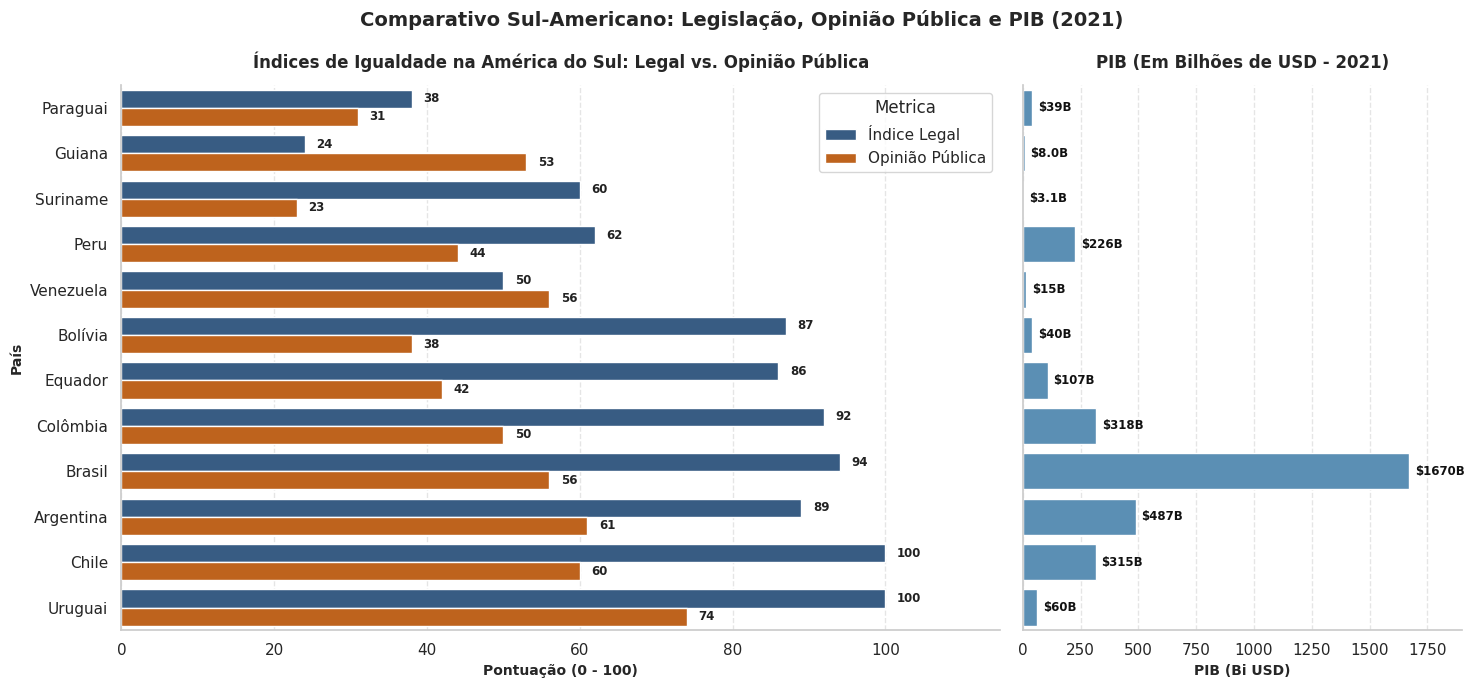

In [0]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 

plt.clf() 
plt.close('all') 

df_americas = spark.table("workspace.default.direitos_americas_vs_pib_2021").toPandas() 

paises_sulamerica = [ 
    'Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana', 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela' 
] 
df_sa = df_americas[df_americas['pais'].isin(paises_sulamerica)].copy()

pt_names = { 
    'Brazil': 'Brasil', 'Argentina': 'Argentina', 'Chile': 'Chile', 'Colombia': 'Colômbia', 'Peru': 'Peru', 'Ecuador': 'Equador', 'Uruguay': 'Uruguai', 'Venezuela': 'Venezuela', 'Paraguay': 'Paraguai', 'Bolivia': 'Bolívia', 'Guyana': 'Guiana', 'Suriname': 'Suriname' 
} 
df_sa['pais_pt'] = df_sa['pais'].replace(pt_names).fillna(df_sa['pais']) 
df_sa = df_sa.sort_values('indice_igualdade', ascending=True)

df_sa_melt = df_sa.melt( 
    id_vars=['pais_pt', 'pib_bilhoes_usd', 'indice_igualdade'],
    value_vars=['indice_igualdade_legal', 'indice_igualdade_pessoas'], 
    var_name='Metrica', 
    value_name='Pontuacao' 
) 
df_sa_melt['Metrica'] = df_sa_melt['Metrica'].map({'indice_igualdade_legal': 'Índice Legal', 'indice_igualdade_pessoas': 'Opinião Pública'}) 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [2, 1]}, sharey=True) 
sns.set_theme(style='whitegrid', font='DejaVu Sans') 

palette_bar = {'Índice Legal': '#2b5c8f', 'Opinião Pública': '#d95f02'} 
sns.barplot(data=df_sa_melt, y='pais_pt', x='Pontuacao', hue='Metrica', palette=palette_bar, ax=ax1) 
ax1.set_title('Índices de Igualdade na América do Sul: Legal vs. Opinião Pública', fontsize=12, fontweight='bold', pad=12) 
ax1.set_xlabel('Pontuação (0 - 100)', fontsize=10, fontweight='bold') 
ax1.set_ylabel('País', fontsize=10, fontweight='bold') 
ax1.set_xlim(0, 115) 
ax1.grid(axis='x', linestyle='--', alpha=0.5) 

for p in ax1.patches: 
    width = p.get_width() 
    if not np.isnan(width) and width > 0: 
        ax1.text(width + 1.5, p.get_y() + p.get_height() / 2, f'{int(width)}', va='center', ha='left', fontsize=8.5, fontweight='bold', color='#222222') 

sns.barplot(data=df_sa, y='pais_pt', x='pib_bilhoes_usd', color='#4c92c3', ax=ax2) 
ax2.set_title('PIB (Em Bilhões de USD - 2021)', fontsize=12, fontweight='bold', pad=12) 
ax2.set_xlabel('PIB (Bi USD)', fontsize=10, fontweight='bold') 
ax2.set_ylabel('') 
ax2.set_xlim(0, 1900) 
ax2.grid(axis='x', linestyle='--', alpha=0.5) 

for p in ax2.patches: 
    width = p.get_width() 
    if not np.isnan(width) and width > 0: 
        ax2.text(width + 25, p.get_y() + p.get_height() / 2, f'${int(width)}B' if width >= 10 else f'${width:.1f}B', va='center', ha='left', fontsize=8.5, fontweight='bold', color='#111111') 

fig.suptitle('Comparativo Sul-Americano: Legislação, Opinião Pública e PIB (2021)', fontsize=14, fontweight='bold', y=0.98) 

sns.despine() 
plt.tight_layout() 
plt.show()
